In [1]:
import pandas as pd
import os

# 换成你存放数据的文件夹路径
path = 'F:\One-Month Internship Sprint Plan\shangchuan_data/'

# 获取所有文件
files = os.listdir(path)

print("==== 10张表的表头摸底 ====\n")
for file in files:
    if file.endswith('.csv'):
        # 关键点：nrows=0，意思是一行数据都不读，只读表头
        df_headers = pd.read_csv(path + file, nrows=0)
        print(f"表名：{file}")
        print(f"包含字段：{df_headers.columns.tolist()}\n")

==== 10张表的表头摸底 ====

表名：auth_user.csv
包含字段：['id', 'password', 'last_login', 'is_superuser', 'username', 'first_name', 'last_name', 'email', 'is_staff', 'is_active', 'date_joined']

表名：order.csv
包含字段：['order_id', 'global_user_id', 'platform', 'order_time', 'payment_time', 'payment_method', 'shipping_address', 'order_status', 'total_amount', 'discount_amount', 'shipping_fee', 'tax_amount', 'promotion_id', 'coupon_code', 'shipping_method']

表名：order_item.csv
包含字段：['order_item_id', 'order_id', 'global_product_id', 'quantity', 'unit_price', 'item_total', 'sku_info']

表名：order_status.csv
包含字段：['code', 'name', 'badge_class', 'description', 'created_at', 'updated_at']

表名：payment_method.csv
包含字段：['code', 'name', 'description', 'created_at', 'updated_at']

表名：platform.csv
包含字段：['code', 'name', 'description', 'created_at', 'updated_at']

表名：product.csv
包含字段：['global_product_id', 'platform_product_id', 'platform', 'product_name', 'category', 'subcategory', 'price', 'brand', 'stock_status', 'tags'

In [2]:
import pandas as pd

# 1. 读入行为表（根据你实际的路径修改）
path = 'F:\One-Month Internship Sprint Plan\shangchuan_data/'
df_behavior = pd.read_csv(path + 'user_behavior.csv')

# 2. 看一眼数据量多大、有没有空值
print("数据维度：", df_behavior.shape)
print("\n缺失值情况：\n", df_behavior.isnull().sum())

# 3. 看看行为类型（behavior_type）到底有哪些值
print("\n行为类型分布：\n", df_behavior['behavior_type'].value_counts())

# 4. 看看设备类型（device_type）有哪些
print("\n设备类型分布：\n", df_behavior['device_type'].value_counts())

数据维度： (21998, 15)

缺失值情况：
 behavior_id              0
global_user_id           0
global_product_id        0
platform                 0
session_id               0
behavior_type            0
behavior_time            0
duration_seconds         0
page_url                 0
referrer              7158
device_type              0
app_version          21998
latitude                 0
longitude                0
extra_data               0
dtype: int64

行为类型分布：
 behavior_type
浏览    5458
加购    4034
收藏    3276
下单    2810
支付    2428
评价    2102
分享    1890
Name: count, dtype: int64

设备类型分布：
 device_type
mobile    21998
Name: count, dtype: int64


In [3]:
import pandas as pd

# 1. 读入行为表（根据你实际的路径修改）
path = 'F:\One-Month Internship Sprint Plan\shangchuan_data/'
df_behavior = pd.read_csv(path + 'user_behavior.csv')

# 2. 基础清洗：删掉全空的 app_version 列
df_behavior = df_behavior.drop(columns=['app_version'])

# 3. 因为行为不是线性的（比如有人直接下单不浏览），我们看看每个行为的独立人数
# 注意：用 nunique() 算独立用户数，因为一个人可能会浏览100次，但只算一个用户
funnel_users = df_behavior.groupby('behavior_type')['global_user_id'].nunique()

print("==== 各环节独立用户数 ====")
print(funnel_users)

# 4. 按照电商转化路径重新排序，计算整体漏斗转化率
# 注意：这里的顺序按照经典漏斗排
order_list = ['浏览', '加购', '收藏', '下单', '支付']
funnel_users = funnel_users.reindex(order_list)

print("\n==== 漏斗转化率 ====")
for i in range(len(funnel_users)):
    if i == 0:
        print(f"{funnel_users.index[i]}: {funnel_users.iloc[i]} 人 (基准)")
    else:
        # 计算相对上一步的转化率
        rate = funnel_users.iloc[i] / funnel_users.iloc[i-1] * 100
        print(f"{funnel_users.index[i]}: {funnel_users.iloc[i]} 人 (转化率: {rate:.2f}%)")

==== 各环节独立用户数 ====
behavior_type
下单    1953
分享    1396
加购    2368
支付    1734
收藏    2148
浏览    2711
评价    1525
Name: global_user_id, dtype: int64

==== 漏斗转化率 ====
浏览: 2711 人 (基准)
加购: 2368 人 (转化率: 87.35%)
收藏: 2148 人 (转化率: 90.71%)
下单: 1953 人 (转化率: 90.92%)
支付: 1734 人 (转化率: 88.79%)


In [4]:
# 1. 看看各个平台（platform）的支付人数
pay_data = df_behavior[df_behavior['behavior_type'] == '支付']
platform_pay = pay_data.groupby('platform')['global_user_id'].nunique().sort_values(ascending=False)
print("==== 各平台支付人数 ====")
print(platform_pay)

# 2. 既然有平台差异，我们再算一下不同平台的“加购到支付”转化率（这里只算加购过的人）
add_cart_data = df_behavior[df_behavior['behavior_type'] == '加购']
platform_add_cart = add_cart_data.groupby('platform')['global_user_id'].nunique()

print("\n==== 各平台加购人数 ====")
print(platform_add_cart)

# 合并计算转化率（注意：这里只是为了演示对比，实际操作中需严谨对待跨表关联）
result = pd.DataFrame({
    '加购人数': platform_add_cart,
    '支付人数': platform_pay
}).fillna(0)

result['加购->支付转化率(%)'] = (result['支付人数'] / result['加购人数'] * 100).round(2)
print("\n==== 各平台加购->支付 转化率对比 ====")
print(result)

==== 各平台支付人数 ====
platform
jd        617
douyin    579
taobao    538
Name: global_user_id, dtype: int64

==== 各平台加购人数 ====
platform
douyin    918
jd        703
taobao    747
Name: global_user_id, dtype: int64

==== 各平台加购->支付 转化率对比 ====
          加购人数  支付人数  加购->支付转化率(%)
platform                          
douyin     918   579         63.07
jd         703   617         87.77
taobao     747   538         72.02


In [5]:
import pandas as pd

# 1. 读取商品表
df_product = pd.read_csv(path + 'product.csv')

# 2. 提取“加购”和“支付”的数据（只要这三个字段：用户、平台、商品ID、行为）
df_add_cart = df_behavior[df_behavior['behavior_type'] == '加购'][['global_user_id', 'platform', 'global_product_id']]
df_pay = df_behavior[df_behavior['behavior_type'] == '支付'][['global_user_id', 'platform', 'global_product_id']]

# 3. 把商品表关联进来（通过 global_product_id 匹配品类 category）
# 也就是：用户加购了哪个商品，这个商品是什么品类？
df_cart_merge = pd.merge(df_add_cart, df_product[['global_product_id', 'category']], on='global_product_id', how='left')
df_pay_merge = pd.merge(df_pay, df_product[['global_product_id', 'category']], on='global_product_id', how='left')

# 4. 按照 平台 + 品类 分组，算独立人数
cart_group = df_cart_merge.groupby(['platform', 'category'])['global_user_id'].nunique().reset_index()
pay_group = df_pay_merge.groupby(['platform', 'category'])['global_user_id'].nunique().reset_index()

# 5. 合并算转化率
result = pd.merge(cart_group, pay_group, on=['platform', 'category'], suffixes=('_加购', '_支付'))
result['转化率(%)'] = (result['global_user_id_支付'] / result['global_user_id_加购'] * 100).round(2)

# 排序，找出转化率最低的 10 个平台+品类组合
result_sorted = result.sort_values(by='转化率(%)')

print("==== 转化率最低的 10 个（平台+品类）组合 ====")
print(result_sorted.head(10))

print("\n==== 转化率最高的 10 个（平台+品类）组合 ====")
print(result_sorted.tail(10))

==== 转化率最低的 10 个（平台+品类）组合 ====
   platform category  global_user_id_加购  global_user_id_支付  转化率(%)
16   taobao     图书文具                154                 74   48.05
2    douyin     服装鞋帽                138                 69   50.00
7    douyin     食品饮料                174                 89   51.15
5    douyin     美妆个护                150                 78   52.00
1    douyin     家居用品                138                 73   52.90
17   taobao     家居用品                141                 76   53.90
20   taobao     电子产品                136                 75   55.15
3    douyin     母婴用品                199                113   56.78
0    douyin     图书文具                161                 94   58.39
4    douyin     电子产品                171                102   59.65

==== 转化率最高的 10 个（平台+品类）组合 ====
   platform category  global_user_id_加购  global_user_id_支付  转化率(%)
22   taobao     运动户外                184                117   63.59
11       jd     母婴用品                158                111   70.25

C:\Users\20725\AppData\Local\Temp\ipykernel_5524\3404838073.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=funnel_data.index, y=funnel_data.values, palette='Blues_d')
findfont: Failed to find font weight bold for SimHei, now using 400.


文件夹已存在：F:\One-Month Internship Sprint Plan\Data-project\chart
图1：漏斗图已保存


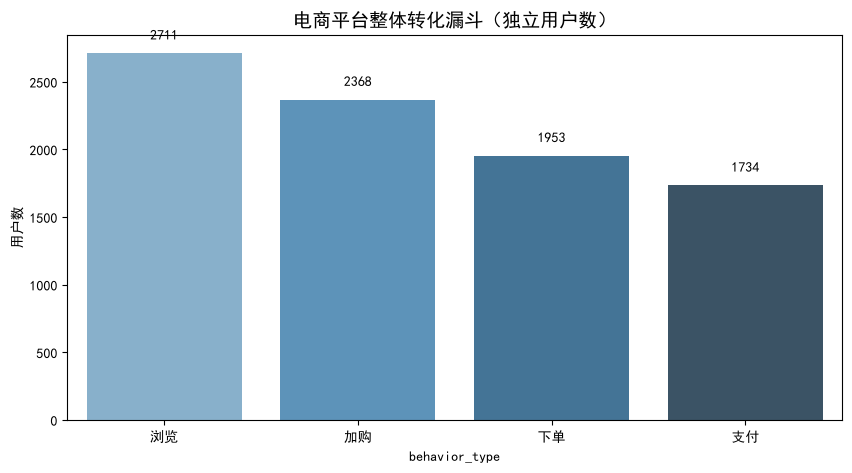

图2：品类转化率图已保存


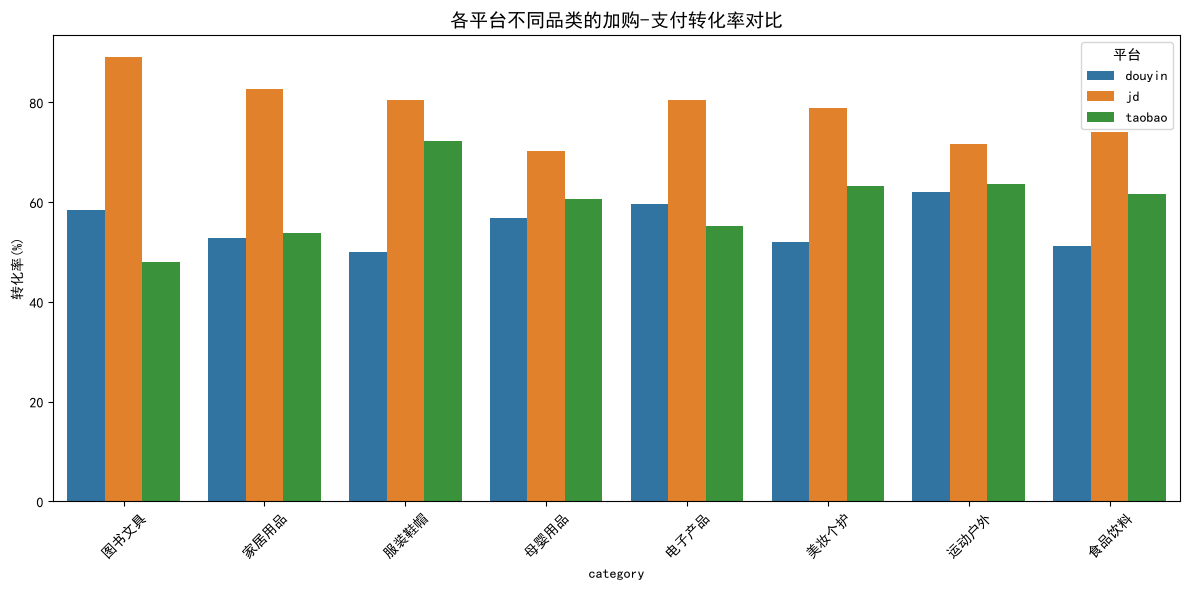

C:\Users\20725\AppData\Local\Temp\ipykernel_5524\3404838073.py:66: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=platform_pay, x='platform', y='global_user_id', palette='Set2')


图3：平台支付人数图已保存


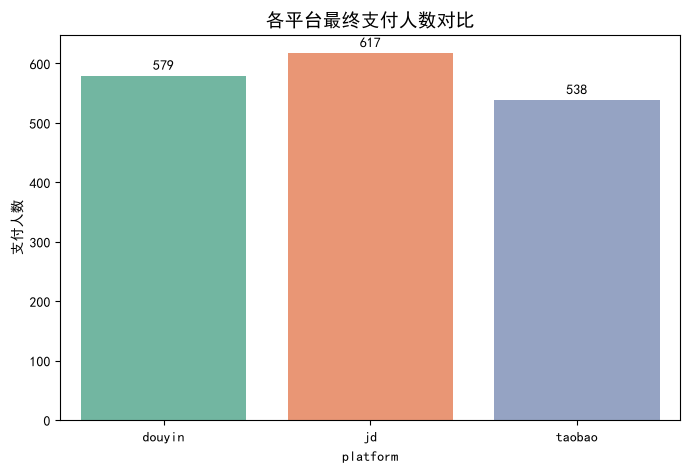


✅ 所有图表已成功保存至：F:\One-Month Internship Sprint Plan\Data-project\chart


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import platform
import os

# ================= 1. 准备保存路径 =================
# 使用 r 前缀防止路径里的反斜杠被转义
save_dir = r'F:\One-Month Internship Sprint Plan\Data-project\chart'

# 如果文件夹不存在，自动创建
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
    print(f"已创建文件夹：{save_dir}")
else:
    print(f"文件夹已存在：{save_dir}")

# ================= 2. 图表样式设置 =================
# 设置中文字体，防止图表里的中文变成方块
if platform.system() == 'Windows':
    plt.rcParams['font.sans-serif'] = ['SimHei']
else:
    plt.rcParams['font.sans-serif'] = ['Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False


# ================= 3. 画图与保存 =================

# 图1：电商平台整体转化漏斗（独立用户数）
funnel_users = df_behavior.groupby('behavior_type')['global_user_id'].nunique()
order_list = ['浏览', '加购', '下单', '支付'] # 只取核心链路
funnel_data = funnel_users.reindex(order_list)

plt.figure(figsize=(10, 5))
sns.barplot(x=funnel_data.index, y=funnel_data.values, palette='Blues_d')
plt.title('电商平台整体转化漏斗（独立用户数）', fontsize=14)
plt.ylabel('用户数')
for i, v in enumerate(funnel_data.values):
    plt.text(i, v + 100, str(v), ha='center', fontweight='bold')

# 保存图1
plt.savefig(os.path.join(save_dir, '01_funnel_chart.png'), dpi=300, bbox_inches='tight')
print("图1：漏斗图已保存")
plt.show()


# 图2：各平台不同品类的加购-支付转化率对比
plt.figure(figsize=(12, 6))
sns.barplot(data=result, x='category', y='转化率(%)', hue='platform')
plt.title('各平台不同品类的加购-支付转化率对比', fontsize=14)
plt.xticks(rotation=45)
plt.legend(title='平台')
plt.tight_layout()

# 保存图2
plt.savefig(os.path.join(save_dir, '02_category_conversion.png'), dpi=300, bbox_inches='tight')
print("图2：品类转化率图已保存")
plt.show()


# 图3：补充图 - 各平台支付总人数对比
# 提取支付数据
pay_data = df_behavior[df_behavior['behavior_type'] == '支付']
platform_pay = pay_data.groupby('platform')['global_user_id'].nunique().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=platform_pay, x='platform', y='global_user_id', palette='Set2')
plt.title('各平台最终支付人数对比', fontsize=14)
plt.ylabel('支付人数')
for i, v in enumerate(platform_pay['global_user_id']):
    plt.text(i, v + 10, str(v), ha='center', fontweight='bold')

# 保存图3
plt.savefig(os.path.join(save_dir, '03_platform_pay.png'), dpi=300, bbox_inches='tight')
print("图3：平台支付人数图已保存")
plt.show()

print(f"\n✅ 所有图表已成功保存至：{save_dir}")